# When cost stands in for need

**How a proxy label can build inequity into a model, even when no sensitive variable is used.**

A health system wants to find patients with the greatest health needs and offer them extra care. "Need" is hard to measure, so the model predicts something easier: next year's **healthcare cost**.

That works only if cost tracks need equally for everyone. If one group spends less for the same level of illness, for example because of access barriers, a cost-based model will quietly rank that group as healthier than it is.

This notebook simulates that situation. It is inspired by a real case: Obermeyer et al. (2019), *Science* 366(6464), 447-453, found that a widely used algorithm predicted costs rather than illness, and that fixing this would raise the share of Black patients receiving extra help from 17.7% to 46.5%.

> **Data note:** all data is **synthetic**. "Group A" and "Group B" are abstract labels, and the size of the spending gap is an illustrative assumption. This is not a reproduction of the original study.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"

## 1. Simulate patients

- **Illness burden** (number of active chronic conditions) has the **same distribution** in both groups.
- **Group B** uses about 35% less healthcare for the same illness. This is the access gap.
- The model sees what a health system typically has: age, last year's cost, last year's visits and recorded diagnoses. Diagnoses are slightly under-recorded for Group B too, since fewer visits mean fewer chances to be diagnosed. **Group membership is not a feature.**

In [2]:
N = 20_000
ACCESS_GAP = 0.65          # Group B spends 65% of what Group A spends for the same illness

group_b = rng.random(N) < 0.30
age = rng.integers(25, 85, N)
# Illness burden: same distribution in both groups, rising with age
conditions_now = rng.poisson(0.4 + 0.035 * (age - 25))
conditions_next = conditions_now + rng.poisson(0.3, N) - rng.binomial(conditions_now, 0.1)

access = np.where(group_b, ACCESS_GAP, 1.0)

def spending(conditions):
    base = 800 + 1_800 * conditions
    return base * access * rng.lognormal(0, 0.35, N)

cost_now = spending(conditions_now)
cost_next = spending(conditions_next)
visits_now = rng.poisson((1 + 2.2 * conditions_now) * access)
# Recorded diagnoses: each condition recorded with 95% chance in Group A, 85% in Group B
diagnoses_now = rng.binomial(conditions_now, np.where(group_b, 0.85, 0.95))

df = pd.DataFrame({
    "age": age, "cost_now": cost_now, "visits_now": visits_now, "diagnoses_now": diagnoses_now,
    "conditions_next": conditions_next, "cost_next": cost_next,
    "group": np.where(group_b, "B", "A"),
})

summary = df.groupby("group").agg(
    patients=("age", "size"),
    mean_conditions_next=("conditions_next", "mean"),
    mean_cost_next=("cost_next", "mean"),
)
summary.style.format({"mean_conditions_next": "{:.2f}", "mean_cost_next": "${:,.0f}"})

,patients,mean_conditions_next,mean_cost_next
group,,,
A,13985,1.60,"$3,908"
B,6015,1.62,"$2,570"


Same illness, different spending. Any model trained on cost will inherit that gap.

## 2. Train two models with the same features

The only difference is the **label**, meaning what the model is asked to predict:

- **Cost model:** predicts next year's cost
- **Need model:** predicts next year's number of chronic conditions

In [3]:
FEATURES = ["age", "cost_now", "visits_now", "diagnoses_now"]
train, test = train_test_split(df, test_size=0.4, random_state=RANDOM_STATE)

cost_model = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(train[FEATURES], train["cost_next"])
need_model = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(train[FEATURES], train["conditions_next"])

test = test.copy()
test["score_cost"] = cost_model.predict(test[FEATURES])
test["score_need"] = need_model.predict(test[FEATURES])

## 3. Who gets flagged for extra care?

The programme has room for the **top 3%** of patients by score. In this setup, the patients who *should* be flagged are the 3% with the highest true illness burden.

In [4]:
TOP = 0.03
k = int(len(test) * TOP)

def flagged(col):
    return test.nlargest(k, col)

truth = test.sort_values("conditions_next", ascending=False, kind="stable").head(k)
cost_flag, need_flag = flagged("score_cost"), flagged("score_need")

rows = []
for name, sel in [("Truth: sickest 3%", truth), ("Cost model", cost_flag), ("Need model", need_flag)]:
    rows.append({
        "Selection": name,
        "Share from Group B": (sel["group"] == "B").mean(),
        "Mean conditions, Group A": sel.loc[sel.group == "A", "conditions_next"].mean(),
        "Mean conditions, Group B": sel.loc[sel.group == "B", "conditions_next"].mean(),
    })
flag_df = pd.DataFrame(rows).set_index("Selection")
print(f"Group B is {(test.group == 'B').mean():.1%} of all patients\n")
flag_df.style.format({"Share from Group B": "{:.1%}",
                      "Mean conditions, Group A": "{:.2f}", "Mean conditions, Group B": "{:.2f}"})

Group B is 29.8% of all patients



,Share from Group B,"Mean conditions, Group A","Mean conditions, Group B"
Selection,,,
Truth: sickest 3%,29.2%,5.55,5.54
Cost model,12.9%,4.78,5.52
Need model,20.0%,4.91,5.31


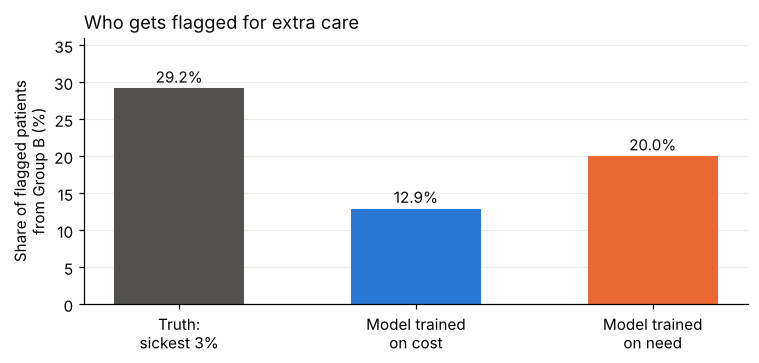

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
labels = ["Truth:\nsickest 3%", "Model trained\non cost", "Model trained\non need"]
vals = flag_df["Share from Group B"].values * 100
colours = [MUTED, BLUE, ORANGE]
bars = ax.bar(labels, vals, color=colours, width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", fontsize=10, color=INK)
ax.set_ylabel("Share of flagged patients\nfrom Group B (%)")
ax.set_ylim(0, 36)
ax.grid(axis="y", color="#ecebe7", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Who gets flagged for extra care", loc="left", fontsize=12, color=INK)
plt.tight_layout()
plt.savefig("who_gets_flagged.png", bbox_inches="tight", facecolor="white")
plt.show()

**Reading the table:**

- The cost model flags far fewer Group B patients than it should.
- The Group B patients it *does* flag are sicker than the Group A patients flagged alongside them. **To be selected, Group B has to be sicker.** This is the same pattern Obermeyer et al. described.
- Changing only the label narrows the gap considerably, with no change to the features or the algorithm. Some gap remains, because the features themselves (past cost, visits and under-recorded diagnoses) still carry part of the access gap. A fully fair model would need better measures of need, not just a better label.

## 4. Same score, different illness

For each score decile, compare the true illness burden of the two groups. If the score meant the same thing for everyone, the lines would overlap.

Under the cost model, Group B is sicker than Group A at almost every score level. The need model narrows this only partly, because its inputs (past cost, visits and diagnoses) still reflect unequal access. Changing the label helps, but it doesn't fix biased inputs.

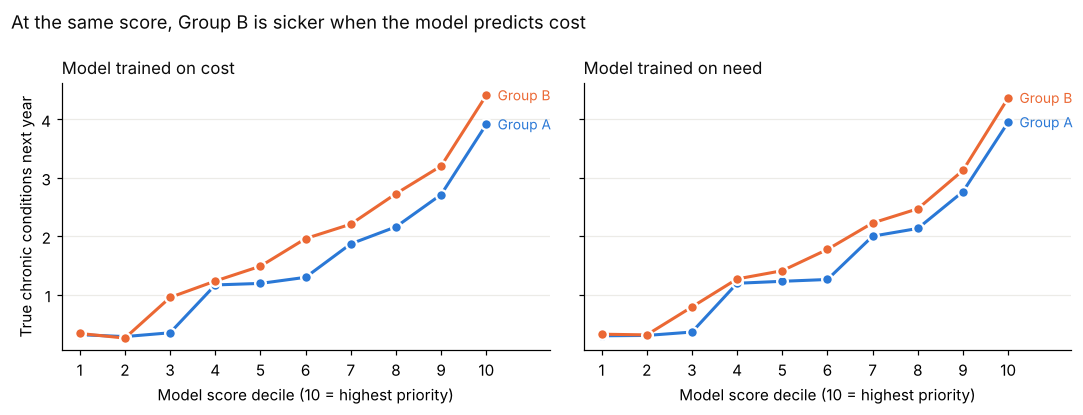

In [6]:
def by_decile(score_col):
    t = test.copy()
    t["decile"] = pd.qcut(t[score_col].rank(method="first"), 10, labels=False) + 1
    return t.groupby(["decile", "group"])["conditions_next"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (col, title) in zip(axes, [("score_cost", "Model trained on cost"),
                                    ("score_need", "Model trained on need")]):
    d = by_decile(col)
    for g, colour in [("A", BLUE), ("B", ORANGE)]:
        ax.plot(d.index, d[g], marker="o", markersize=7, linewidth=2, color=colour,
                markeredgecolor="white", markeredgewidth=1.5)
        ax.text(10.25, d[g].iloc[-1], f"Group {g}", color=colour, va="center", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Model score decile (10 = highest priority)")
    ax.set_xticks(range(1, 11))
    ax.set_xlim(0.6, 11.4)
    ax.grid(axis="y", color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("True chronic conditions next year")
fig.suptitle("At the same score, Group B is sicker when the model predicts cost",
             x=0.01, ha="left", fontsize=12, color=INK)
plt.tight_layout()
plt.savefig("cost_vs_need.png", bbox_inches="tight", facecolor="white")
plt.show()

## Takeaways

- **The label is the most important modelling decision.** The model did exactly what it was asked: it predicted cost accurately. The problem was the question.
- **Removing a sensitive variable doesn't remove bias.** Group membership was never a feature. The bias came in through cost and visits.
- **Check whether the score means the same thing for every group**, for example by comparing true outcomes at the same score, as in Section 4.
- **This matters for any cost or claims data**, including insurance and benefits. Cost measures care received, which is not the same as care needed.

*Synthetic data, illustrative assumptions. Built as a companion to a LinkedIn post on proxy variables.*